# 03 - Compound events and the production-risk comparison

Classifies each year (normal / heat_only / drought_only / concurrent / sequential)
and compares yield in compound years against normal years.

Requires `piedmont_production.csv` (nb 01) and `piedmont_climate_indices.csv`
(nb 02).

In [1]:
# Locate the project root and make src/ + config importable.
import os, sys
d = os.getcwd()
while not os.path.exists(os.path.join(d, "config.py")) and os.path.dirname(d) != d:
    d = os.path.dirname(d)
os.chdir(d)
if d not in sys.path:
    sys.path.insert(0, d)
print("Project root:", d)

Project root: /Users/shreyshukla/Documents/ICS Project


In [2]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import config
from src import compound

## 1. How a year is classified

A compound event is treated as an extreme, so severity uses the top/bottom
`config.COMPOUND_SEVERITY_PCTL` fraction of years (default 0.25, i.e. quartile):

- Heat year: summer heatwave-days in the hottest quartile.
- Drought year: growing-season rainfall in the driest quartile.
- Concurrent: a single month that is both hot and dry.
- Sequential: heat and drought in different months, not overlapping.
- Normal: neither, used as the comparison group.

`COMPOUND_SEVERITY_PCTL` is the largest lever on the result. Section 4 shows the
sensitivity (the dose-response); see ANALYSIS.md for the full discussion.

In [3]:
merged = compound.build()
merged.to_csv(config.COMPOUND_CSV, index=False)
merged[['year','yield_per_ha','yield_anom_pct','summer_heatwave_days','growing_precip_mm','category']]

,year,yield_per_ha,yield_anom_pct,summer_heatwave_days,growing_precip_mm,category
0,2006,86.198124,12.824896,0,514.283333,normal
1,2007,74.852018,-2.450456,11,431.583333,drought_only
2,2008,68.616665,-10.962267,0,576.116667,normal
3,2009,77.286714,-0.142621,10,532.483333,normal
4,2010,85.475461,9.965288,7,558.550000,normal
5,2011,70.133822,-10.156129,0,478.300000,normal
6,2012,70.703050,-9.810961,10,530.733333,normal
7,2013,75.562939,-4.018637,10,712.016667,normal
8,2014,78.632884,-0.539076,7,583.166667,normal
9,2015,82.311476,3.677989,23,614.216667,heat_only


## 2. The headline comparison

In [4]:
h = compound.headline(merged)
print('Compound-event years (%d): %s' % (h['n_compound'], h['compound_years']))
print('Normal years: %d' % h['n_normal'])
if h['pct_difference'] == h['pct_difference']:
    d = 'lower' if h['pct_difference'] < 0 else 'higher'
    print('\nIn compound-event years, Piedmont yield was %.1f%% %s than in normal years' % (abs(h['pct_difference']), d))
    print('(%.1f vs %.1f quintals/ha).' % (h['mean_yield_compound'], h['mean_yield_normal']))
else:
    print('Not enough compound or normal years; widen the record or revisit thresholds.')

Compound-event years (2): [2017, 2022]
Normal years: 10

In compound-event years, Piedmont yield was 5.4% lower than in normal years
(74.3 vs 78.6 quintals/ha).


## 3. Sensitivity: the dose-response

In [5]:
rows = []
for pctl, label in [(1/3, 'tercile (loose)'), (0.25, 'quartile'), (0.20, 'top/bottom 20%')]:
    prev = config.COMPOUND_SEVERITY_PCTL
    config.COMPOUND_SEVERITY_PCTL = pctl
    m = compound.build(); hh = compound.headline(m)
    config.COMPOUND_SEVERITY_PCTL = prev
    rows.append({'definition': label, 'compound_years': hh['compound_years'], 'pct_diff': round(hh['pct_difference'], 1)})
pd.DataFrame(rows)

,definition,compound_years,pct_diff
0,tercile (loose),"[2007, 2016, 2017, 2021, 2022]",0.4
1,quartile,"[2017, 2022]",-5.4
2,top/bottom 20%,[2017],-10.7


## 4. Yield timeline with compound years marked

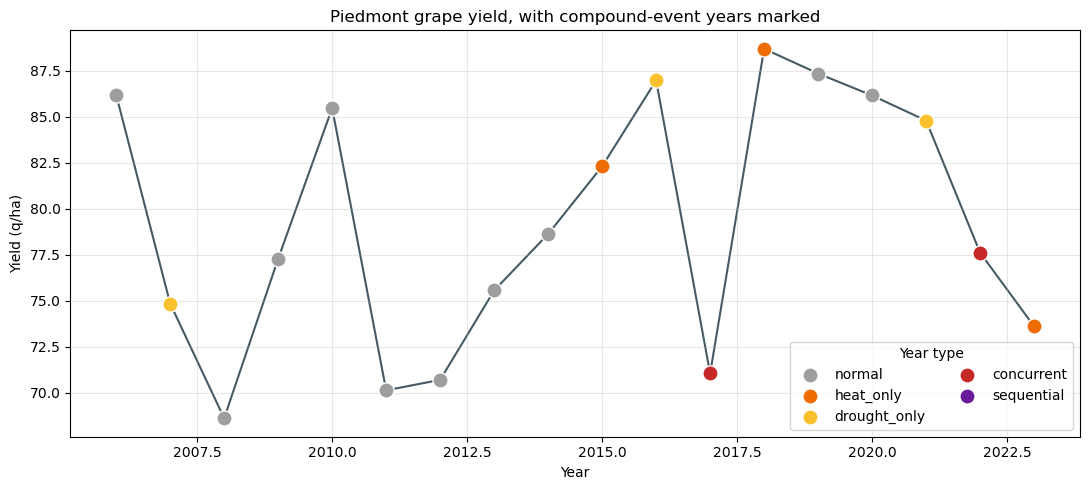

In [6]:
colors = {'normal':'#9e9e9e','heat_only':'#ef6c00','drought_only':'#fbc02d','concurrent':'#c62828','sequential':'#6a1b9a'}
fig, ax = plt.subplots(figsize=(11, 5))
ax.plot(merged.year, merged.yield_per_ha, color='#455a64', zorder=1)
for cat, c in colors.items():
    sub = merged[merged.category == cat]
    ax.scatter(sub.year, sub.yield_per_ha, s=120, color=c, label=cat, zorder=2, edgecolor='white')
ax.set_xlabel('Year'); ax.set_ylabel('Yield (q/ha)'); ax.legend(title='Year type', ncol=2)
ax.set_title('Piedmont grape yield, with compound-event years marked'); ax.grid(alpha=.3)
plt.tight_layout(); plt.show()

Output: `data/processed/piedmont_compound_analysis.csv`. Next,
`04_dashboard.ipynb` presents this interactively.